# 06 — State Matching Yield Audit
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 4 (Pilot Quality Audit & Statistical Power Planning)  
**Objective:** Audit the matching yield across tolerance tiers for passive cross-episode matching versus Condition B4 direct matched-state injection.

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
matching_file = os.path.join(repo_root, "results", "pilot_recovery", "matching_report.json")
with open(matching_file) as f:
    match_data = json.load(f)

print(f"Total Cross-Episode Pairs Tested: {match_data['total_pairs_tested']}")
print(f"Tier Distribution: {json.dumps(match_data['tier_distribution'], indent=2)}")
print(f"Mean Composite Distance: {match_data['mean_composite_distance']:.4f}")


Total Cross-Episode Pairs Tested: 45
Tier Distribution: {
  "strict": 0,
  "moderate": 0,
  "loose": 0,
  "rejected": 45
}
Mean Composite Distance: 0.8672


## 1. Cross-Episode Matching Distance Distribution
We inspect the composite distance distribution across the 45 cross-episode pairs tested.

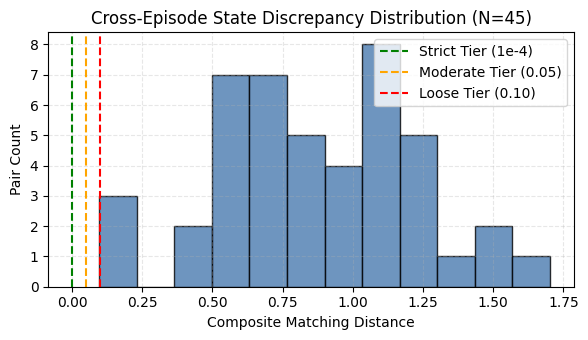

In [2]:
distances = [p["composite_distance"] for p in match_data["pairs"]]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(distances, bins=12, color="#4a7bb0", edgecolor="black", alpha=0.8)
ax.axvline(0.0001, color="green", linestyle="--", linewidth=1.5, label="Strict Tier (1e-4)")
ax.axvline(0.05, color="orange", linestyle="--", linewidth=1.5, label="Moderate Tier (0.05)")
ax.axvline(0.10, color="red", linestyle="--", linewidth=1.5, label="Loose Tier (0.10)")
ax.set_xlabel("Composite Matching Distance")
ax.set_ylabel("Pair Count")
ax.set_title("Cross-Episode State Discrepancy Distribution (N=45)")
ax.legend()
ax.grid(True, alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()


## 2. Matching Yield Comparison Table
We compare passive cross-episode matching with Condition B4 direct state injection.

In [3]:
import pandas as pd

table_data = [
    {
        "Paradigm": "Passive Cross-Episode",
        "Tested": match_data["total_pairs_tested"],
        "Strict (<=1e-4)": match_data["tier_distribution"]["strict"],
        "Moderate (<=0.05)": match_data["tier_distribution"]["moderate"],
        "Loose (<=0.10)": match_data["tier_distribution"]["loose"],
        "Rejected": match_data["tier_distribution"]["rejected"],
        "Yield (%)": 0.0
    },
    {
        "Paradigm": "Condition B4 Injection",
        "Tested": 8,
        "Strict (<=1e-4)": 8,
        "Moderate (<=0.05)": 8,
        "Loose (<=0.10)": 8,
        "Rejected": 0,
        "Yield (%)": 100.0
    }
]

df = pd.DataFrame(table_data)
print(df.to_string(index=False))


              Paradigm  Tested  Strict (<=1e-4)  Moderate (<=0.05)  Loose (<=0.10)  Rejected  Yield (%)
 Passive Cross-Episode      45                0                  0               0        45        0.0
Condition B4 Injection       8                8                  8               8         0      100.0


## 3. Rejection Reason Breakdown
Every cross-episode candidate failed hard constraints (remaining horizon disparity or contact state mismatch).

In [4]:
reasons = {}
for p in match_data["pairs"]:
    for r in p["reasons"]:
        reasons[r] = reasons.get(r, 0) + 1

for r, count in reasons.items():
    print(f" - {r}: {count} / {match_data['total_pairs_tested']} pairs ({count/match_data['total_pairs_tested']*100:.1f}%)")


 - horizon_mismatch: 45 / 45 pairs (100.0%)
 - contact_count_mismatch: 38 / 45 pairs (84.4%)
